# Module 11.3 — FastText 🧠

Bro, FastText solves one of the important limitations of Word2Vec and GloVe: how can we represent rare words, misspellings, and words we've never seen before?

Word2Vec and GloVe typically learn one vector per complete word. FastText goes further by representing words using their character n-grams.

## 1. Character n-grams

A character n-gram is a sequence of \\(n\\) consecutive characters.

Consider the word `where`, represented with boundary markers as `<where>`.

Its character n-grams include:

- Character 3-grams: `<wh`, `whe`, `her`, `ere`, `re>`
- Character 4-grams: `<whe`, `wher`, `here`, `ere>`


The boundary markers help distinguish word beginnings and endings.

FastText commonly uses character n-grams of different lengths, rather than relying on one fixed n-gram size. These subword units help represent recurring spelling patterns.

## 2. Subword information: how FastText builds a word vector

FastText extends the Skip-gram or CBOW approach by representing a word through its character n-grams.

For a word \\(w\\), its representation can be understood as a combination of its subword vectors:

\\[ \mathbf{v}\_w \approx \sum\_{g\in G_w}\mathbf{z}\_g \\]

Here, \\(G_w\\) is the set of character n-grams associated with the word, and \\(\mathbf{z}\_g\\) is the learned vector for each n-gram. FastText's original formulation also includes a word-level representation.

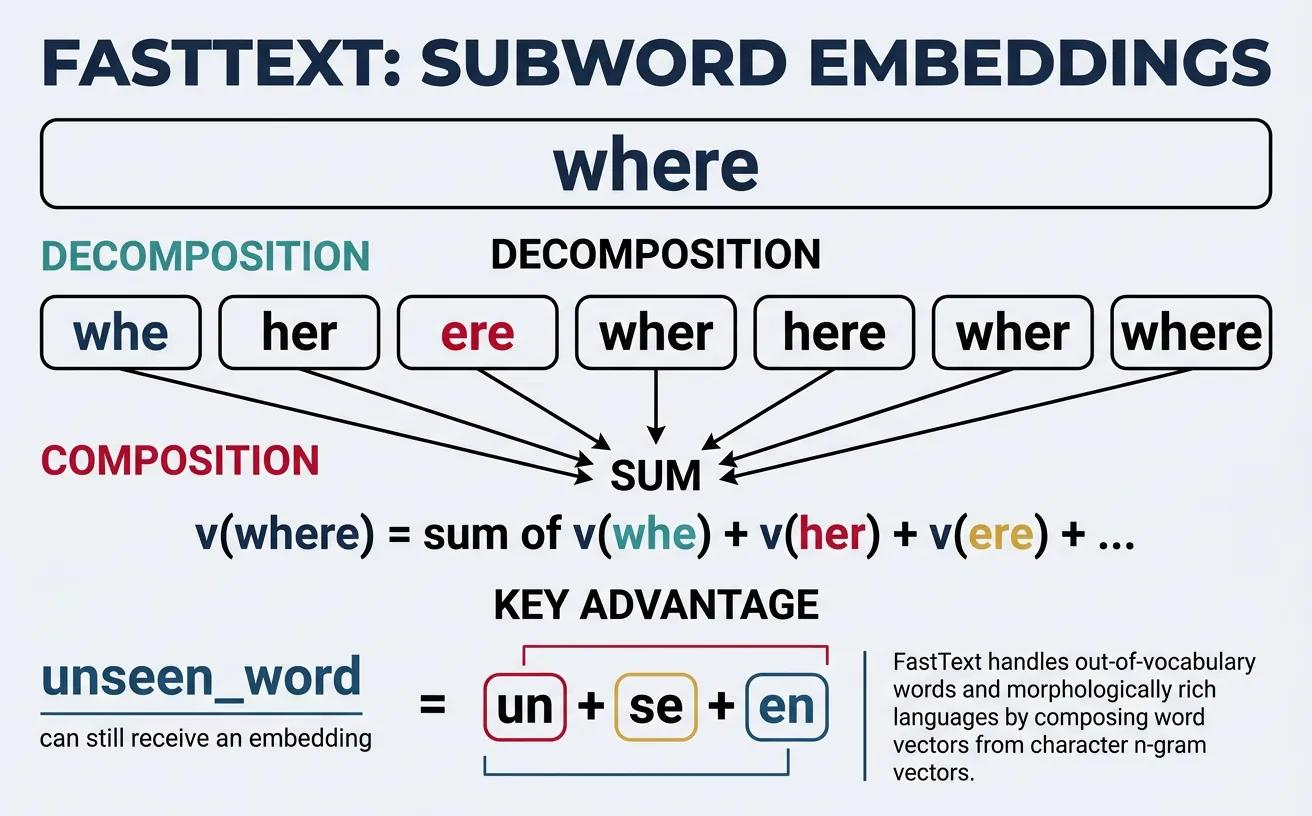

Imagine the model has learned useful subword representations for `play`, `playing`, and `played`. Shared character patterns can help the model represent related forms similarly, although the final vectors are not guaranteed to be identical or close in every case.

This is the core insight: the model learns from the internal structure of words, not just from whole-word identities.

## 3. Rare words and unknown words

Consider these words:

- `connect`
- `connected`
- `connecting`
- `reconnecting`

A traditional whole-word embedding model needs sufficient training evidence for each complete word. FastText can also learn from recurring pieces such as `connect`, `ing`, and `ed` wherever those pieces occur in its n-gram representation.

Why this helps

Rare words

Even when a complete word appears infrequently, its character n-grams may have been observed many times in other words.

Out-of-vocabulary (OOV) words

A trained FastText model can construct a vector for an unseen word from its available character n-grams, even if the complete word was absent from training.

Important limitation

An unseen word made of familiar character pieces can receive a vector, but that does not guarantee its meaning is understood correctly. Completely unfamiliar character patterns can also limit the benefit.

The official FastText implementation explicitly supports obtaining vectors for out-of-vocabulary words from a trained model.&#x20;

[image](https://www.google.com/s2/favicons?domain=https://github.com\&sz=32)

GitHub

+1



## 4. Why FastText helps with morphologically rich languages

Morphology is the study of how words are formed from smaller meaningful units, such as roots, prefixes, and suffixes.

For example, in English:

- `help`
- `helpful`
- `helpless`
- `helpfulness`

These words share a root and related character patterns.

In languages such as Tamil, Finnish, Turkish, and Czech, words can have many inflected or derived forms. Tamil, for instance, can express grammatical information through suffixes attached to a word stem.


FastText can reuse learned character n-gram representations across different word forms. This is particularly valuable when a language has a large number of distinct word forms and many of them occur infrequently. The official FastText research describes its benefits for morphologically rich languages.
One caveat: character n-grams capture spelling patterns, not guaranteed linguistic morphemes. They may cross meaningful word boundaries, and their effectiveness depends on the language and training data.

## 5. Final comparison

| Feature                | Word2Vec / GloVe                          | FastText                                       |
| ---------------------- | ----------------------------------------- | ---------------------------------------------- |
| Whole-word vectors     | Yes                                       | Yes, combined with subword information         |
| Character n-grams      | No, not in their standard forms           | Yes                                            |
| Rare word handling     | Relies heavily on whole-word evidence     | Can benefit from shared subword evidence       |
| Unseen word vectors    | Generally unavailable                     | Can construct vectors from available n-grams   |
| Morphological patterns | Not explicitly modeled at character level | Captured indirectly through character patterns |

## What you should remember 🎯

1. FastText extends Word2Vec-style learning with character n-gram representations.
2. Character n-grams are overlapping sequences of characters.
3. Subword information helps share statistical evidence between related word forms.
4. FastText can generate vectors for many unseen words using a trained model.
5. It is particularly useful for rare words and morphologically rich languages.
6. Subword similarity is not the same as true semantic understanding.

---